# Proyecto del 1er Parcial  — Predicción del rendimiento académico con aprendizaje automático

| | |
|---|---|
| **Integrantes** | JORDAN EDUARDO CHANCAY REYES · ERICK RICARDO MUÑIZ RUIZ · DAVID ALEXANDER PAREDES FLORES · SAUL HUMBERTO ZAMBRANO CEDEÑO |
| **Paralelo** | CDDEIA-ELMA-4-1|
| **Grupo** | B |
| **Fecha** | 22 de noviembre de 2026|
| **Asignatura** | APRENDIZAJE AUTOMÁTICO|
| **Docente** | ING. DARWIN ALEXA RODRIGUEZ MERCHÁN MSc|
| | |


## Contexto y objetivo

Una institución educativa quiere identificar a tiempo a los estudiantes en riesgo de reprobar para ofrecerles tutorías. Construimos un pipeline completo sobre el dataset *Student Performance / Student Alcohol Consumption* (Cortez & Silva, 2008), que trae dos archivos con las mismas 33 variables: `student-mat.csv` (Matemática) y `student-por.csv` (Portugués). Con ellos buscamos responder dos preguntas:

1. **Regresión lineal:** ¿qué nota final (`G3`) obtendrá un estudiante?
2. **Regresión logística:** ¿aprobará (`G3 ≥ 10`) o reprobará?

# Parte 1. Análisis exploratorio de datos (EDA)

Como el dataset tiene dos materias, el EDA se hace **por separado para Matemática y para Portugués** y se compara al final de cada sección.

## 1.1 Carga y estructura del dataset

In [ ]:
# ============================================================
# Librerías y configuración general 
# ============================================================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)

In [ ]:
# ============================================================
# 1.1 Carga de los dos datasets
# ============================================================
import kagglehub
from kagglehub import KaggleDatasetAdapter

def cargar(archivo):
    return kagglehub.dataset_load(
        KaggleDatasetAdapter.PANDAS, "uciml/student-alcohol-consumption", archivo)


datasets = {
    "Matemática": cargar("student-mat.csv"),
    "Portugués":  cargar("student-por.csv"),
}

for nombre, d in datasets.items():
    print(f"--- {nombre} ---")
    display(d.head())

--- Matemática ---


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


--- Portugués ---


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,0,yes,no,no,no,yes,yes,yes,no,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,no,yes,yes,yes,yes,yes,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,no,no,yes,yes,no,no,4,3,2,1,2,5,0,11,13,13


In [30]:
# ============================================================
# 1.1 Estructura: tipos de variables, nulos y estadísticas descriptivas
# ============================================================
for nombre, d in datasets.items():
    print(f"=== {nombre} ===")
    d.info()
    print()
    print("Valores nulos en total:", d.isna().sum().sum())
    print("Estadísticas de las variables numéricas:")
    display(d.describe().T.round(2))
    print("Estadísticas de las variables categóricas:")
    display(d.select_dtypes(exclude="number").describe().T)
    print()

=== Matemática ===
<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null

,count,mean,std,min,25%,50%,75%,max
age,395.0,16.70,1.28,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.75,1.09,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.52,1.09,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.45,0.70,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.04,0.84,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.33,0.74,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.94,0.90,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.24,1.00,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.11,1.11,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.48,0.89,1.0,1.0,1.0,2.0,5.0


Estadísticas de las variables categóricas:


,count,unique,top,freq
school,395,2,GP,349
sex,395,2,F,208
address,395,2,U,307
famsize,395,2,GT3,281
Pstatus,395,2,T,354
Mjob,395,5,other,141
Fjob,395,5,other,217
reason,395,4,course,145
guardian,395,3,mother,273
schoolsup,395,2,no,344



=== Portugués ===
<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      649 non-null    str  
 1   sex         649 non-null    str  
 2   age         649 non-null    int64
 3   address     649 non-null    str  
 4   famsize     649 non-null    str  
 5   Pstatus     649 non-null    str  
 6   Medu        649 non-null    int64
 7   Fedu        649 non-null    int64
 8   Mjob        649 non-null    str  
 9   Fjob        649 non-null    str  
 10  reason      649 non-null    str  
 11  guardian    649 non-null    str  
 12  traveltime  649 non-null    int64
 13  studytime   649 non-null    int64
 14  failures    649 non-null    int64
 15  schoolsup   649 non-null    str  
 16  famsup      649 non-null    str  
 17  paid        649 non-null    str  
 18  activities  649 non-null    str  
 19  nursery     649 non-null    str  
 20  higher      649 non-null

,count,mean,std,min,25%,50%,75%,max
age,649.0,16.74,1.22,15.0,16.0,17.0,18.0,22.0
Medu,649.0,2.51,1.13,0.0,2.0,2.0,4.0,4.0
Fedu,649.0,2.31,1.10,0.0,1.0,2.0,3.0,4.0
traveltime,649.0,1.57,0.75,1.0,1.0,1.0,2.0,4.0
studytime,649.0,1.93,0.83,1.0,1.0,2.0,2.0,4.0
failures,649.0,0.22,0.59,0.0,0.0,0.0,0.0,3.0
famrel,649.0,3.93,0.96,1.0,4.0,4.0,5.0,5.0
freetime,649.0,3.18,1.05,1.0,3.0,3.0,4.0,5.0
goout,649.0,3.18,1.18,1.0,2.0,3.0,4.0,5.0
Dalc,649.0,1.50,0.92,1.0,1.0,1.0,2.0,5.0


Estadísticas de las variables categóricas:


,count,unique,top,freq
school,649,2,GP,423
sex,649,2,F,383
address,649,2,U,452
famsize,649,2,GT3,457
Pstatus,649,2,T,569
Mjob,649,5,other,258
Fjob,649,5,other,367
reason,649,4,course,285
guardian,649,3,mother,455
schoolsup,649,2,no,581


### **Interpretación de 1.1**

**Estructura.** Ambos archivos cuentan con las mismas 33 columnas: 16 variables numéricas enteras (como la edad, la educación de los padres, las escalas de 1 a 5, las ausencias y las notas `G1`, `G2` y `G3`) y 17 variables categóricas de texto (como la escuela, el sexo, el trabajo de los padres y el apoyo escolar). La diferencia entre ambos archivos está en la cantidad de estudiantes: Matemática tiene 395 y Portugués 649. Además, ninguno presenta valores nulos, por lo que no es necesario realizar ningún tratamiento para completar datos faltantes. Según la documentación del dataset, alrededor de 382 estudiantes cursan ambas materias y aparecen en los dos archivos. Por esta razón, no se deben combinar como si fueran estudiantes diferentes.

**Estadísticas de la nota final (**`G3`**).** Al comparar las notas finales, se observa que Portugués tiene un promedio más alto y notas menos dispersas que Matemática.

| Estadística         | Matemática | Portugués |
| ------------------- | ---------- | --------- |
| Media               | 10,42      | 11,91     |
| Desviación estándar | 4,58       | 3,23      |
| Mediana             | 11         | 12        |
| Mínimo / máximo     | 0 / 20     | 0 / 19    |

Esto indica que, en general, los estudiantes obtienen mejores resultados en Portugués y sus calificaciones son más homogéneas. En cambio, en Matemática existe una mayor variación entre las notas, lo que refleja que algunos estudiantes tienen un rendimiento considerablemente más bajo que otros.

**Ausencias (**`absences`**).** En ambos archivos, las ausencias presentan una distribución bastante desigual, ya que la mayoría de los estudiantes falta pocas veces, mientras que un grupo reducido acumula muchas ausencias. En Matemática, la mediana es 4, la media es 5,71 y el máximo es 75. En Portugués, la mediana es 2, la media es 3,66 y el máximo es 32. Esto explica por qué la media es mayor que la mediana en las dos materias: unos pocos estudiantes con un número elevado de ausencias hacen que el promedio aumente.

**Otras variables.** Las notas `G1`, `G2` y `G3` mantienen medias relativamente similares dentro de cada materia. Por ejemplo, en Matemática son 10,9 / 10,7 / 10,4, lo que muestra que el rendimiento promedio de los estudiantes no presenta cambios muy marcados a lo largo del año.

Por otro lado, las variables ordinales (`famrel`, `freetime`, `goout`, `Dalc`, `health`) utilizan una escala del 1 al 5. En particular, `Dalc`, que representa el consumo de alcohol durante los días de semana, tiene una mediana de 1 en ambos archivos, lo que indica que la mayoría de los estudiantes reporta un consumo bajo.

Finalmente, entre las variables categóricas se observa que la mayoría de los estudiantes pertenece a la escuela GP, vive en zonas urbanas y tiene intención de continuar sus estudios superiores (`higher = yes`). Esta última categoría reúne a 375 de 395 estudiantes en Matemática y a 580 de 649 en Portugués, por lo que el grupo que no tiene intención de seguir estudiando es relativamente pequeño.

## 1.2 Distribuciones

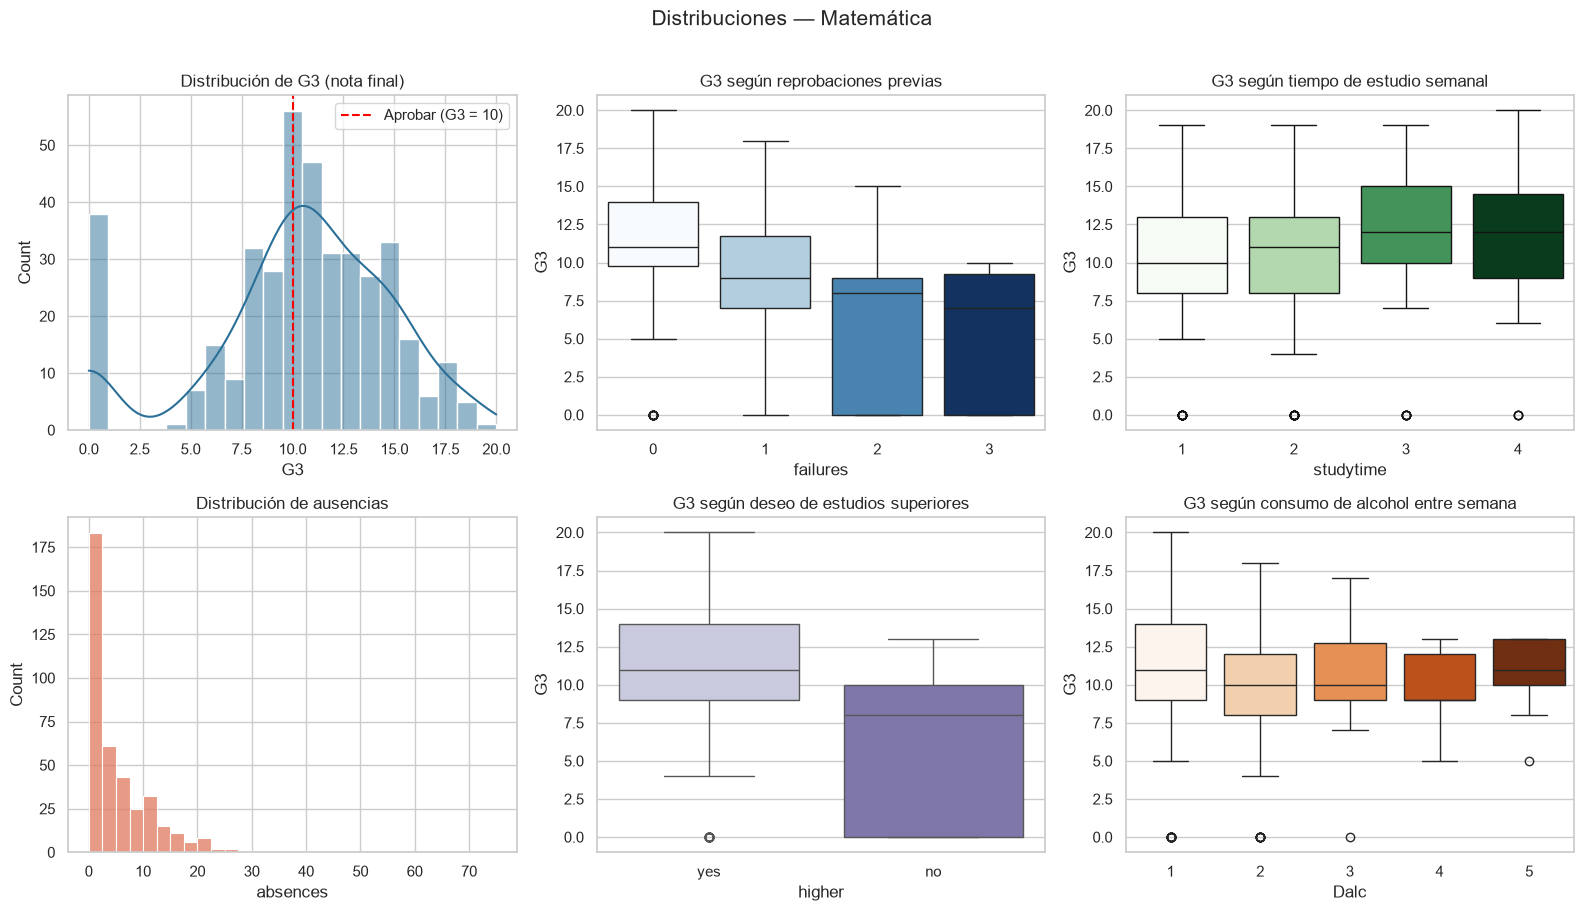

Matemática: estudiantes con G3 = 0: 38 (9.6%)


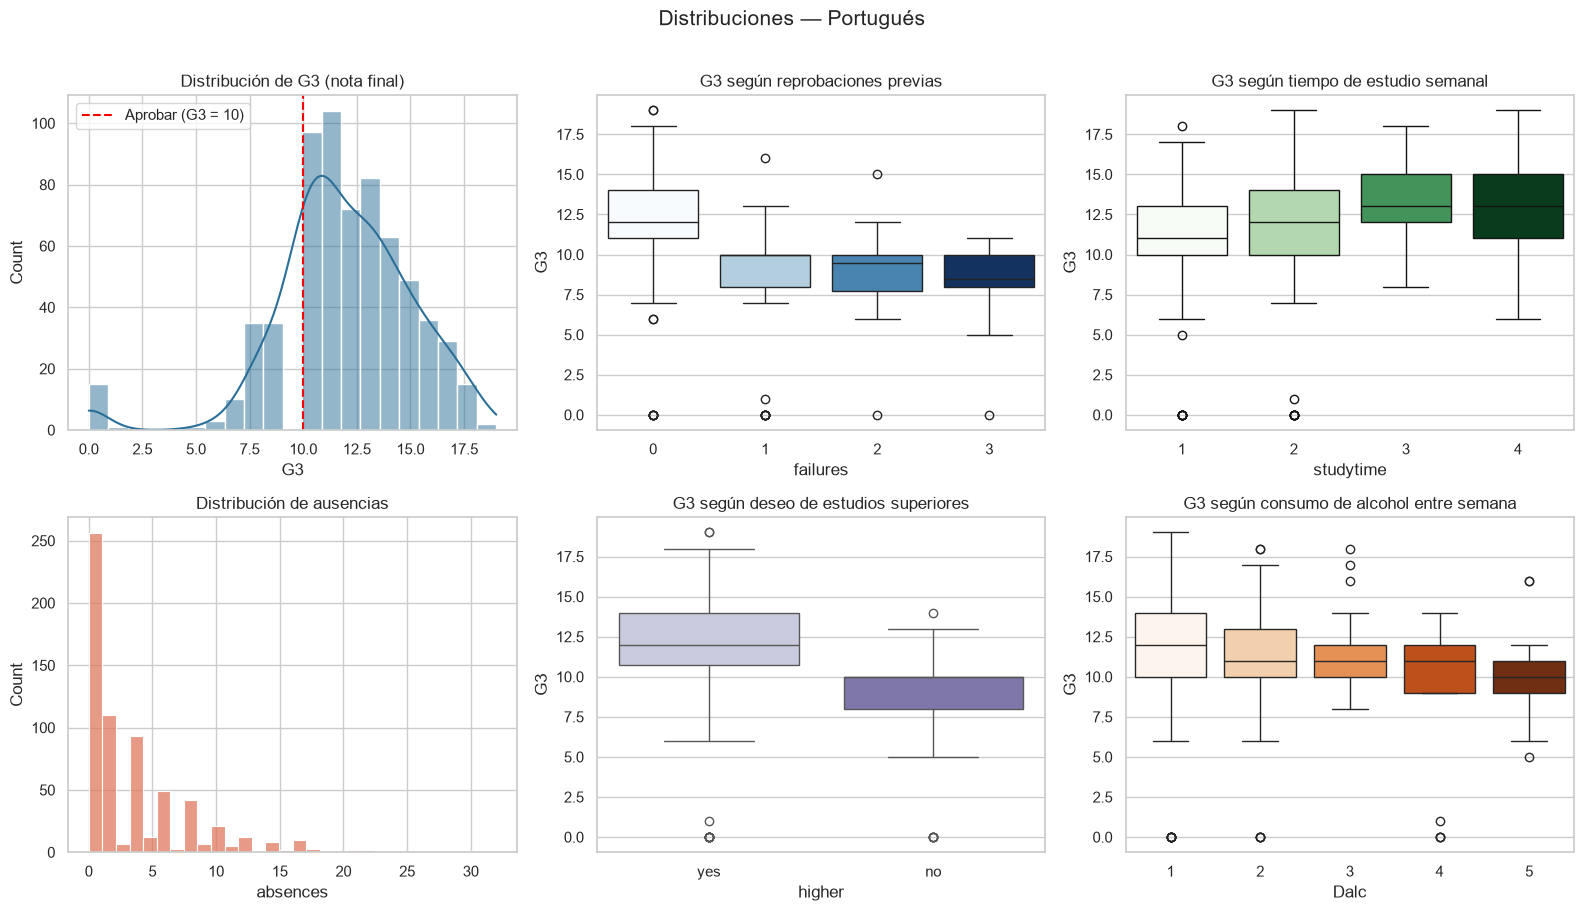

Portugués: estudiantes con G3 = 0: 15 (2.3%)


In [ ]:
# ============================================================
# 1.2 Distribuciones: G3 y cinco variables relevantes
# ============================================================
def graficar_distribuciones(d, nombre):
    fig, axes = plt.subplots(2, 3, figsize=(16, 9))
    fig.suptitle(f"Distribuciones — {nombre}", fontsize=15, y=1.01)

   
    sns.histplot(d["G3"], bins=21, kde=True, ax=axes[0, 0], color="#2a6f97")
    axes[0, 0].axvline(10, color="red", ls="--", label="Aprobar (G3 = 10)")
    axes[0, 0].set_title("Distribución de G3 (nota final)")
    axes[0, 0].legend()

    
    boxes = [("failures", "Blues",   (0, 1), "G3 según reprobaciones previas"),
             ("studytime", "Greens", (0, 2), "G3 según tiempo de estudio semanal"),
             ("higher",    "Purples", (1, 1), "G3 según deseo de estudios superiores"),
             ("Dalc",      "Oranges", (1, 2), "G3 según consumo de alcohol entre semana")]
    for var, paleta, pos, titulo in boxes:
        sns.boxplot(data=d, x=var, y="G3", hue=var, palette=paleta,
                    legend=False, ax=axes[pos])
        axes[pos].set_title(titulo)

 
    sns.histplot(d["absences"], bins=30, ax=axes[1, 0], color="#e07a5f")
    axes[1, 0].set_title("Distribución de ausencias")

    plt.tight_layout()
    plt.show()
    n0 = (d["G3"] == 0).sum()
    print(f"{nombre}: estudiantes con G3 = 0: {n0} ({n0 / len(d):.1%})")

for nombre, d in datasets.items():
    graficar_distribuciones(d, nombre)

Sí, puedo hacerla más breve sin perder los datos numéricos ni las variables importantes. Aquí tienes una versión más resumida y natural:

### **Interpretación de 1.2**

**Distribución de&#x20;**`G3`**.** Las notas finales no presentan una distribución normal en ninguna de las dos materias. En ambas existe un grupo de estudiantes con `G3 = 0`, separado del resto por un intervalo entre 0 y 5. Estos casos representan 38 estudiantes (9,6 %) en Matemática y 15 (2,3 %) en Portugués, y probablemente corresponden a estudiantes que no se presentaron o abandonaron el curso, como se confirma en 1.4. Excluyendo estos casos, Matemática concentra sus notas entre 8 y 15, con mayor dispersión alrededor de la nota de aprobación (10). En Portugués, la mayoría se encuentra entre 10 y 15, por lo que hay más estudiantes aprobados y las notas de quienes reprueban suelen estar entre 7 y 9.

**Reprobaciones previas (**`failures`**).** En ambas materias, las notas medianas disminuyen a medida que aumentan las reprobaciones previas. En Portugués, la caída es más notable entre 0 y 1 reprobación, mientras que las categorías 2 y 3 presentan resultados similares y pocos estudiantes. En Matemática, la disminución continúa hasta 3 reprobaciones y existe mayor dispersión en las notas.

**Tiempo de estudio (**`studytime`**).** Se observa una mejora gradual en las notas hasta `studytime = 3`, especialmente en Portugués. En Matemática la tendencia es más débil y las cajas se superponen casi por completo. En ninguna materia el nivel 4 muestra una mejora respecto al nivel 3.

**Ausencias (**`absences`**).** Ambas distribuciones se concentran en valores bajos, pero presentan una cola larga hacia la derecha, más extrema en Matemática, donde se alcanzan 75 ausencias. Debido a esta asimetría, conviene revisar los valores extremos o considerar una transformación antes de modelar.

**Deseo de estudios superiores (**`higher`**).** Los estudiantes que responden `no` presentan notas medianas de `G3` más bajas en ambas materias. Sin embargo, este grupo es pequeño: 20 estudiantes en Matemática y 69 en Portugués, por lo que la diferencia debe interpretarse con cautela.

**Alcohol entre semana (**`Dalc`**).** Se observa una ligera tendencia a obtener notas más bajas con mayor consumo, especialmente en Portugués. Sin embargo, las cajas se solapan y los niveles 4 y 5 tienen pocos estudiantes. En Matemática no se aprecia un patrón claro, por lo que esta relación es débil.

## 1.3 Correlaciones

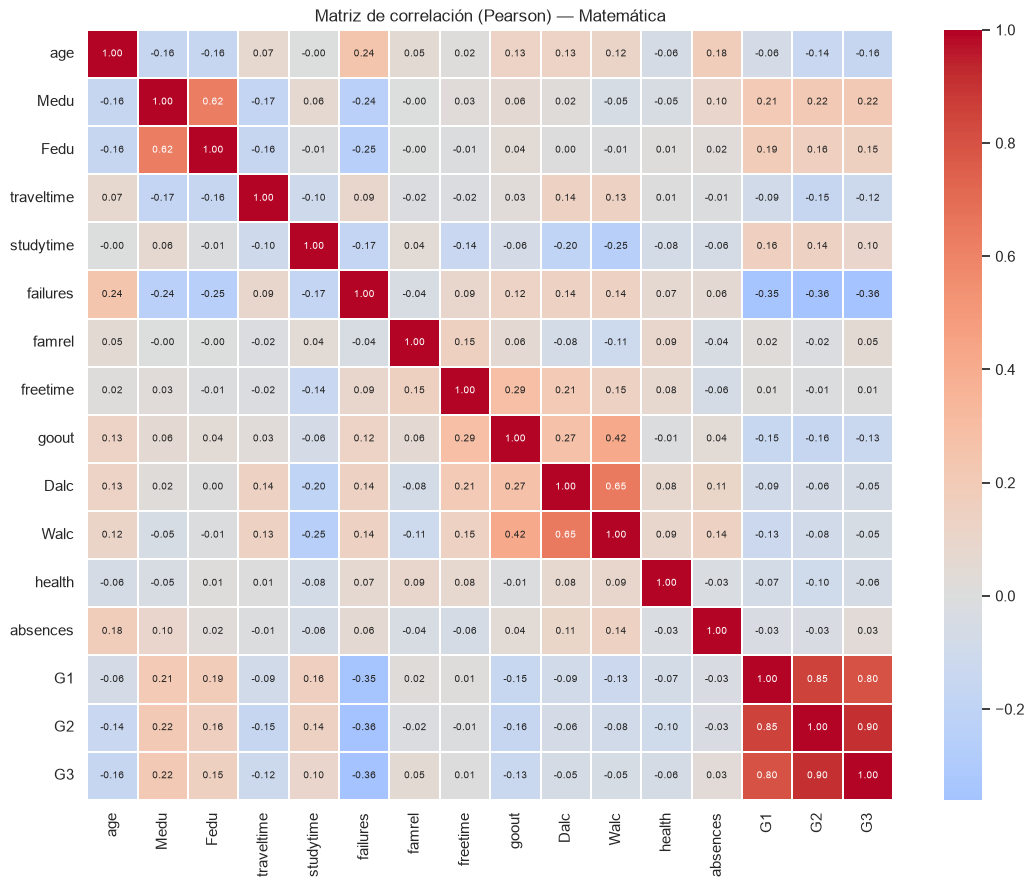

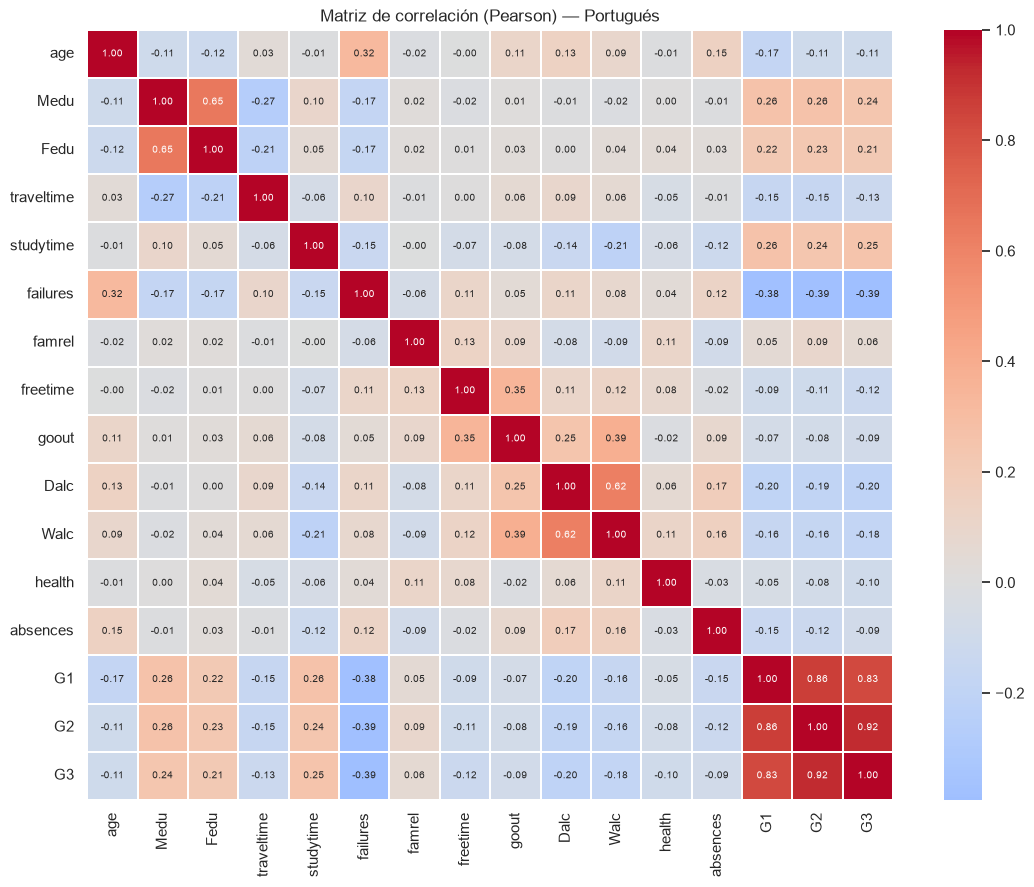

,Matemática,Portugués
G2,0.905,0.919
G1,0.801,0.826
failures,-0.360,-0.393
Medu,0.217,0.240
age,-0.162,-0.107
Fedu,0.152,0.212
goout,-0.133,-0.088
traveltime,-0.117,-0.127
studytime,0.098,0.250
health,-0.061,-0.099


In [ ]:
# ============================================================
# 1.3 Matriz de correlación (Pearson) de las variables numéricas
# ============================================================
corr_g3 = {}
for nombre, d in datasets.items():
    corr = d.select_dtypes(include="number").corr()
    corr_g3[nombre] = corr["G3"].drop("G3")

    plt.figure(figsize=(13, 10))
    sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f",
                annot_kws={"size": 7}, linewidths=.3)
    plt.title(f"Matriz de correlación (Pearson) — {nombre}")
    plt.show()

tabla = pd.DataFrame(corr_g3)
display(tabla.sort_values("Matemática", key=abs, ascending=False).round(3))

### **Interpretación de 1.3**

**Lo que se repite en las dos materias.** Las variables más relacionadas con `G3` son las notas previas: `G2` (0,91 en Matemática y 0,92 en Portugués) y `G1` (0,80 y 0,83). Después aparece `failures` (−0,36 y −0,39), que es la variable no académica con mayor relación. También se observa una relación positiva con la educación de la madre (`Medu`: 0,22 y 0,24) y del padre (`Fedu`: 0,15 y 0,21).

**Lo que cambia.** `studytime` tiene una relación casi nula con `G3` en Matemática (r ≈ 0,10), pero mayor en Portugués (0,25). El consumo de alcohol (`Dalc` −0,21 y `Walc` −0,18) muestra una relación negativa más relevante en Portugués, mientras que en Matemática es débil. Otras variables, como `absences`, `freetime` y `famrel`, presentan correlaciones prácticamente nulas en Matemática y bajas en Portugués (|r| ≤ 0,13).

**Relaciones entre predictores.** En el heatmap de Portugués, `G1` y `G2` presentan una correlación de 0,86, `Medu` y `Fedu` de 0,65, y `Dalc` y `Walc` de 0,62. Estas relaciones indican posible multicolinealidad en la regresión lineal de la Parte 2, lo que podría generar inestabilidad en los coeficientes si se incluyen juntas.

**Precauciones.** Pearson mide únicamente relaciones lineales y algunas variables son ordinales. Además, los estudiantes con `G3 = 0`, especialmente en Matemática, pueden afectar las correlaciones de `absences` y otras variables. Por último, una correlación alta no implica causalidad.

## 1.4 Hallazgos

In [33]:
# ============================================================
# 1.4 Datos de apoyo para los hallazgos
# ============================================================
for nombre, d in datasets.items():
    print(f"---------- {nombre} ----------")
    for var, etiqueta in [("failures", "reprobaciones previas"),
                          ("higher", "deseo de estudios superiores"),
                          ("studytime", "tiempo de estudio"),
                          ("Dalc", "alcohol entre semana (Dalc)")]:
        print(f"G3 promedio según {etiqueta}:")
        print(d.groupby(var)["G3"].agg(["count", "mean"]).round(2), "\n")

    print("Correlación G2-G3:", round(d["G2"].corr(d["G3"]), 3),
          "| G1-G3:", round(d["G1"].corr(d["G3"]), 3))
    print("Ausencias promedio con G3 = 0:", round(d.loc[d["G3"] == 0, "absences"].mean(), 2),
          "| con G3 > 0:", round(d.loc[d["G3"] > 0, "absences"].mean(), 2), "\n")

---------- Matemática ----------
G3 promedio según reprobaciones previas:
          count   mean
failures              
0           312  11.25
1            50   8.12
2            17   6.24
3            16   5.69 

G3 promedio según deseo de estudios superiores:
        count   mean
higher              
no         20   6.80
yes       375  10.61 

G3 promedio según tiempo de estudio:
           count   mean
studytime              
1            105  10.05
2            198  10.17
3             65  11.40
4             27  11.26 

G3 promedio según alcohol entre semana (Dalc):
      count   mean
Dalc              
1       276  10.73
2        75   9.25
3        26  10.50
4         9   9.89
5         9  10.67 

Correlación G2-G3: 0.905 | G1-G3: 0.801
Ausencias promedio con G3 = 0: 0.0 | con G3 > 0: 6.32 

---------- Portugués ----------
G3 promedio según reprobaciones previas:
          count   mean
failures              
0           549  12.51
1            70   8.64
2            16   8.81
3  

### **Hallazgos principales**

**Hallazgo 1 — Las reprobaciones previas son la principal señal de riesgo.** En Matemática, el promedio de `G3` pasa de 11,25 sin reprobaciones a 8,12 con una y 5,69 con tres, una diferencia de aproximadamente 5,6 puntos. En Portugués, pasa de 12,51 (549 estudiantes) a 8,64 con una reprobación y 8,07 con tres, una caída de unos 4,4 puntos. La mayor disminución ocurre con la primera reprobación, mientras que los grupos con 2 y 3 son pequeños (16 y 14 estudiantes).

**Hallazgo 2 — Las notas previas anticipan fuertemente la nota final.** La correlación entre `G2` y `G3` es 0,91 en Matemática y 0,919 en Portugués, mientras que entre `G1` y `G3` es 0,80 y 0,826. Esto muestra que el rendimiento suele mantenerse a lo largo del curso. Aunque los modelos que incluyan estas variables tendrán buenos resultados, `G2` se conoce cuando el curso está casi terminado, por lo que su utilidad para intervenir a tiempo es limitada.

**Hallazgo 3 — Los hábitos tienen mayor relación con el rendimiento en Portugués.** En Matemática, el promedio pasa de 10,05 con `studytime = 1` a 11,40 con `studytime = 3` (r = 0,10). En Portugués aumenta de 10,84 a 13,23 (r = 0,25), aunque el nivel 4 (13,06) no supera al 3. Respecto al alcohol (`Dalc`), en Portugués el promedio baja de 12,30 (nivel 1) a 8,94 (nivel 4), pero sube a 10,24 en el nivel 5. Como los niveles 4 y 5 tienen solo 17 estudiantes cada uno, no se puede establecer una tendencia clara. En Matemática tampoco se observa un patrón definido.

**Hallazgo 4 — Los estudiantes con&#x20;**`G3 = 0`**&#x20;presentan un comportamiento diferente.** En ambas materias, estos estudiantes tienen un promedio de 0 ausencias: 38 en Matemática (9,6 %) y 15 en Portugués (2,3 %), frente a 3,75 ausencias del resto en Portugués. Esto sugiere que podrían no haberse presentado al examen o haber abandonado el curso sin que se registraran sus ausencias. Esta situación afecta la relación entre `absences` y las notas, especialmente en Matemática, y deberá considerarse en la Parte 2.

**Hallazgo 5 —&#x20;**`higher`**&#x20;marca una diferencia importante en el rendimiento.** Los estudiantes que no desean continuar sus estudios superiores promedian 6,80 en Matemática (20 estudiantes), frente a 10,61 del resto. En Portugués, el promedio es 8,80 (69 estudiantes), frente a 12,28. La diferencia es de aproximadamente 3,5 a 3,8 puntos en ambas materias, aunque el tamaño reducido de estos grupos puede afectar la estabilidad de los modelos.

**Comparación y conclusión.** Ambas materias presentan patrones similares: las notas previas y las reprobaciones son los factores más relacionados con el rendimiento final, mientras que `higher` también marca una diferencia importante. Matemática presenta mayor dificultad y variabilidad, mientras que en Portugués los hábitos de estudio y consumo de alcohol muestran relaciones algo más visibles. Por estas diferencias, conviene entrenar un modelo independiente para cada materia en la Parte 2.